## Data Exploratory Steps

- Masked everyone's name as XXX to maintain anonymity.
- For participants with unrealistic chip times (e.g., completing 5KM in 5–10 minutes), replaced their chip times with their gun times.
- Removed all DNS (Did Not Start) and DNF (Did Not Finish) participants who had no recorded finishing times.
- For participants without a recorded 5KM split time, estimated their split by dividing their chip time by 2, assuming they maintained a constant pace throughout the entire 10KM race.

## Explanation of Positional Rankings

### Tie-Breaking Rules
If two runners have the same **chip time**, the runner with the faster **gun time** will receive the better ranking. Also, if two runners have the same **gun time**, the runner with the faster **chip time** will receive the better ranking.

### Timing Methods
- **Gun Time:** The time elapsed from the official race start until the runner crosses the finish line.
- **Chip Time:** The actual time taken by the runner, measured from crossing the starting line to crossing the finish line.

Rankings are calculated separately using both timing methods.

### Ranking Categories
1. **Overall Position:** Includes all runners, regardless of gender or race category.
2. **Gender Position:** Includes all runners of the same gender, regardless of race category.
3. **Category Position**: Includes only runners belonging to the same race category and gender. (Interestingly, original websitem Sporthive appears to calculate category positions separately by gender but displays the total number of participants across both genders within that category, which seems inconsistent.)

### Ranking Calculation
- **Gun-Time Ranking:** Runners are primarily sorted by gun time, with chip time used as the tiebreaker.
- **Chip-Time Ranking:** Runners are primarily sorted by chip time, with gun time used as the tiebreaker.

All positions start from 1, with lower finishing times receiving better rankings.

In [1]:
# ======================= 1. IMPORTS AND SETTINGS =======================
import textwrap 
import pandas as pd
import matplotlib.pyplot as plt

# Excel file with the results
DATA_FILE = "garmin_run_10km_results_final.xlsx"

# Text shown at the top of the result card
EVENT_TITLE = "Garmin Run Marathon Series Singapore 2026"
EVENT_SUB = "Running @ Singapore, 21KM (shortened to 10km), 25/10/2026, by Krispy Noodles"

In [2]:
# ======================= 2. LOAD AND PREPARE THE DATA =======================

# helper functions
def hms_to_sec(s):

    # converting Hour Min Seconds to purely seconds to be used for calculation later
    h, m, sec = str(s).split(":")
    return int(h) * 3600 + int(m) * 60 + float(sec)

# to remove the milliseconds if there is
def clean(s):                       # "00:36:08.000" -> "00:36:08" (drops the milliseconds, even though everyone's milliseconds is 000 LOL)
    return str(s).split(".")[0]

# rounding half up seconds if 217.6 it will be rounded up to 218s
# adding 0.5 seconds to the total number of seconds, converting it into an integer
# then returning it as a mins and seconds that are whole numbers
def mmss(sec):
    sec = int(sec + 0.5)
    return f"{sec // 60:02d}:{sec % 60:02d}"

# reading the Excel file rename the columns to be shorter
df = pd.read_excel(DATA_FILE).rename(columns={
    "Name": "name", "Bib Number": "bib", "Gender": "gender", "Category": "category",
    "Gun Time": "gun", "5K Split Time": "k5", "Chip Time": "chip"})

# reading the bib as text so  "233" matches whether typed as 233 or "233"
df["bib"] = df["bib"].astype(str).str.strip()

# creating a copy of each of gun time, chip time and 5k time converted to seconds, so we can rank and do maths
# (columns end in _s: gun_s, k5_s, chip_s)
for col in ("gun", "k5", "chip"):

    # adding a _s to each of these col as the new col name
    df[col + "_s"] = df[col].map(hms_to_sec)

# creating unique positions for everyone, such that if they have the same chip time, then we will consider the gun time for the position
# dataframe, first as in sorting by chip or gun time, then secondary sorting which is the tiebreaker condition
# group as in it could be gender or open category or competive
def unique_position(frame, first, then, group=None):


    # sorts by the first condition then the second
    # stable keeps the order in ties
    order = frame.sort_values([first, then], kind="stable")

    # if there is a category or gender, then it will only count for that order in that group
    # 1, 2, 3... within each group
    if group:
        pos = order.groupby(group).cumcount() + 1                
    else:
        # else it is across everyone
        # 1, 2, 3... across everyone
        pos = pd.Series(range(1, len(order) + 1), index=order.index)   
    
    return pos.reindex(frame.index)     

# --- positions, ranked TWO ways ---
# By gun time = clock starts at the starting gun of the first pen (matches the website's positions)
df["overall_pos"] = unique_position(df, "gun_s", "chip_s")
df["gender_pos"] = unique_position(df, "gun_s", "chip_s", "gender")
# category
df["cat_pos"] = unique_position(df, "gun_s", "chip_s", ["category", "gender"])

# By chip time = clock starts when the runner crosses the start line and stops when the runner crosses the finishing line (real running time)
df["overall_pos_chip"] = unique_position(df, "chip_s", "gun_s")
df["gender_pos_chip"] = unique_position(df, "chip_s", "gun_s", "gender")
df["cat_pos_chip"] = unique_position(df, "chip_s", "gun_s", ["category", "gender"])

# --- the "Out of ..." totals shown under each position ---
# number of runners of that gender
df["gender_total"] = df.groupby("gender")["bib"].transform("count")        

# number of runners in that category of that gender
df["cat_total"] = (df.groupby(["category", "gender"])["bib"].transform("count"))

# everyone that ran
total_runners = len(df)

# --- leg speeds (km/h) for the split chart, plus the field average ---

# divide by 60s*60min = 3600 seconds to get the km/hr
# Calculate the average speed (km/h) for the first 5KM
df["speed_5"] = 5 / (df["k5_s"] / 3600)        

# Calculate the average speed (km/h) for the second 5KM
df["speed_10"] = 5 / ((df["chip_s"] - df["k5_s"]) / 3600)    # 5-10 km speed
avg_speed = [df["speed_5"].mean(), df["speed_10"].mean()]                  # the orange line on the chart

print(f"Loaded {total_runners} runners ({df['chip_s'].notna().sum()} with a finish time).")
print(f"Average leg speeds: 0-5km {avg_speed[0]:.2f} km/h, 5-10km {avg_speed[1]:.2f} km/h")

Loaded 2232 runners (2232 with a finish time).
Average leg speeds: 0-5km 9.97 km/h, 5-10km 10.10 km/h


In [3]:
# ======================= 3. FUNCTIONS THAT BUILD THE RESULT CARD =======================

# Colours used on the card
TEAL, TEAL_DARK, GREEN, ORANGE = "#54d3db", "#4abcc4", "#7fbfa8", "#f5a623"
CHIP_BLUE = "#2a8f97"   # colour of the "by chip time" position numbers

def fmt_pos(p):
    """Position as a whole number, or '-' if there isn't one."""
    return "-" if pd.isna(p) else str(int(p))

# function to find runner by bib number
def find_runner(bib_number):
    q = str(bib_number).strip().lower()           # tidy the input: text, no spaces, lowercase
    hit = df[df["bib"].str.lower() == q]          # rows whose bib matches exactly
    if hit.empty:
        return None                               # nobody has that bib
    return hit.iloc[0]                            # the single matching runner (one row)

# just retrieving all of the data and putting them nicely
def make_card(r, name):
    """Draws the whole result card for one runner (r = their row, name = name to display)."""
    gender_label = {"M": "Male", "F": "Female"}.get(r["gender"], r["gender"])
    chip_s, k5_s = r["chip_s"], r["k5_s"]
    speed = 10 / (chip_s / 3600)                   # average speed over 10 km, in km/h
    pace = mmss(chip_s / 10)                       # average pace, per km

    # The page is one figure split into 4 stacked rows: header / times / positions / chart
    fig = plt.figure(figsize=(10, 11.8), facecolor="white")
    gs = fig.add_gridspec(4, 1, height_ratios=[1.35, 2.3, 1.5, 3.3], hspace=0.1,
                          left=0.06, right=0.97, top=0.97, bottom=0.05)

    # --- ROW 1: header (event title, event details, runner name, bib and gender) ---
    h = fig.add_subplot(gs[0]); h.set_xlim(0, 10); h.set_ylim(0, 4); h.axis("off")
    h.text(0.05, 3.3, EVENT_TITLE, color=TEAL, fontsize=19, fontweight="bold", va="center")
    h.text(0.05, 2.5, EVENT_SUB, fontsize=9.5, va="center")
    h.text(0.05, 1.3, name, color=TEAL, fontsize=17, va="center")
    h.text(0.05, 0.5, f"Bib #{r['bib']},  {gender_label}", fontsize=9.5, va="center")

    # --- ROW 2: times panel (left, light teal) + splits table (right, darker teal) ---
    ax = fig.add_subplot(gs[1]); ax.set_xlim(0, 10); ax.set_ylim(0, 4); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 3, 4, color=TEAL))
    ax.add_patch(plt.Rectangle((3, 0), 7, 4, color=TEAL_DARK))
    ax.text(1.5, 3.3, "GUN TIME", color="white", ha="center", va="center", fontsize=11)
    ax.text(1.5, 2.45, clean(r["gun"]), color="white", ha="center", va="center", fontsize=30)
    # chip time, speed and pace listed under the big gun time (label on the left, value on the right)
    for y, label, val in [(1.5, "Chip time", clean(r["chip"])),
                          (1.0, "Speed", f"{speed:.2f} km/h"),
                          (0.5, "Pace", f"{pace} min/km")]:
        ax.text(1.45, y, label, color="white", ha="right", va="center", fontsize=10)
        ax.text(1.6, y, val, color="white", ha="left", va="center", fontsize=10, fontweight="bold")

    # splits table: column headings, then one row per split
    cols = [3.4, 5.0, 6.9, 8.6]                    # x positions of the 4 columns
    for x, t in zip(cols, ["NAME", "SPLITS KM", "PACE", "TIME"]):
        ax.text(x, 3.3, t, color="white", fontweight="bold", fontsize=9.5, va="center")
    table = []

    # two rows: first 5 km, then the finish (pace of the 2nd half = time for 2nd 5 km / 5)
    table.append(("Split 5k", "5 KM", mmss(k5_s / 5), clean(r["k5"])))
    table.append(("Finish", "10 KM", mmss((chip_s - k5_s) / 5), clean(r["chip"])))

    step, y = 0.75, 2.6                            # row spacing and starting height
    for row in table:
        ax.plot([3.3, 9.9], [y + step / 2] * 2, color="white", alpha=0.35, lw=0.8)   # thin line above the row
        for x, v in zip(cols, row):
            ax.text(x, y, v if x != cols[2] else f"{v} min/km", color="white", fontsize=9.5, va="center")
        y -= step

    # --- ROW 3: positions (overall / gender / category), each shown by gun time AND by chip time ---
    p = fig.add_subplot(gs[2]); p.set_xlim(0, 10); p.set_ylim(0, 4); p.axis("off")
    for x, label, gun_pos, chip_pos, total in [
        (1.67, "Overall position", r["overall_pos"], r["overall_pos_chip"], total_runners),
        (5.0, gender_label, r["gender_pos"], r["gender_pos_chip"], r["gender_total"]),
        (8.33, r["category"], r["cat_pos"], r["cat_pos_chip"], r["cat_total"]),
    ]:
        p.text(x, 3.5, textwrap.fill(str(label), 30), ha="center", va="center", fontsize=9.5)   # column title

        # two big numbers side by side: gun-time position (left) and chip-time position (right)
        for dx, pos, cap, col in [(-0.8, gun_pos, "by gun time", TEAL), (0.8, chip_pos, "by chip time", CHIP_BLUE)]:
            p.text(x + dx, 2.3, str(int(pos)), ha="center", va="center", fontsize=20, fontweight="bold", color=col)
            p.text(x + dx, 1.4, cap, ha="center", va="center", fontsize=8.5, color="gray")
        p.text(x, 0.4, f"Out of {int(total)}", ha="center", va="center", fontsize=9.5)

    # --- ROW 4: split chart - the runner's speed in each half vs the field average ---
    c = fig.add_subplot(gs[3])

    # 1. Overall average (all runners)
    overall_avg = [
        df["speed_5"].mean(),
        df["speed_10"].mean()
    ]

    # 2. Gender average (same gender as selected runner)
    gender_df = df[df["gender"] == r["gender"]]

    gender_avg = [
        gender_df["speed_5"].mean(),
        gender_df["speed_10"].mean()
    ]

    # 3. Category average (same category AND gender)
    category_df = df[
        (df["category"] == r["category"]) &
        (df["gender"] == r["gender"])
    ]

    category_avg = [
        category_df["speed_5"].mean(),
        category_df["speed_10"].mean()
    ]

    # 4. Individual runner
    runner_speed = [
        r["speed_5"],
        r["speed_10"]
    ]

    # Plot all four lines
    c.plot([5, 10], overall_avg,
        marker="o", color=ORANGE, label="Overall Average")

    c.plot([5, 10], gender_avg,
        marker="o", color="royalblue",
        label=f"{gender_label} Average")

    c.plot([5, 10], category_avg,
        marker="o", color="purple",
        label=f"{gender_label} {r['category']} Average")

    c.plot([5, 10], runner_speed,
        marker="o", color=GREEN, linewidth=2.5,
        label=f'Runner {bib_number}')

    # Chart formatting
    c.set_title("SPLIT CHART", loc="left", fontsize=12)
    c.set_xlabel("km")
    c.set_ylabel("km/h")
    c.set_xticks([5, 10])
    c.margins(x=0.15)
    c.grid(alpha=0.3)
    c.legend(loc="best", frameon=False)
    
    return fig

def show_runner(bib_number, name=None):
    """Looks up a bib number and shows that runner's result card."""

    # 1) look the runner up; stop if the bib doesn't exist
    r = find_runner(bib_number)
    
    if r is None:
        print("No runner found for:", bib_number)
        return

    # 2) if no name was given, use the masked name from the Excel file
    if name is None:
        name = r["name"]

    # 3) runners with no finish time have nothing to show
    if pd.isna(r["chip_s"]):
        print(f"{name} (bib {r['bib']}) has no finish time recorded - nothing to show.")
        return

    # 4) draw the card
    fig = make_card(r, name)
    fname = f"result_bib_{r['bib']}.png"

    # to save the figure as an image, uncomment the line bewlo
    # fig.savefig(fname, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    # print(f"Saved as {fname}")

## Enter a bib number
Change `bib_number` in the cell below (keep the quotes), then run the cell. Change it and run again for the next person.

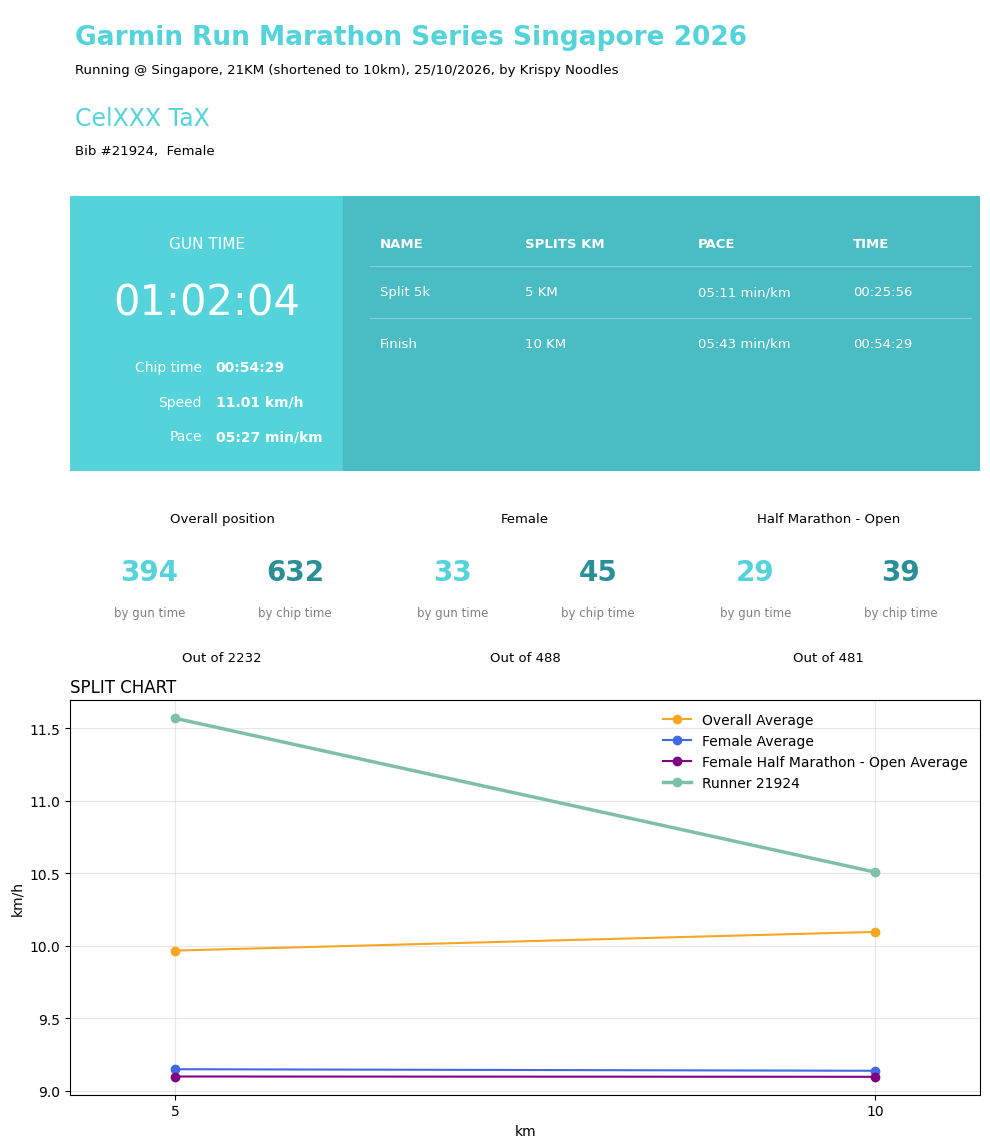

In [4]:
# ======================= 4. TYPE A BIB NUMBER HERE =======================
bib_number = "21924"
name = 'Joey Lim'

show_runner(bib_number)              # shows the masked name, if the name isnt entered
# show_runner(bib_number, name)      # use this line instead to show your name typed aboce

# Notes on the positions:
# Halfmarathon-open excludes runners from the Competitive Category
# Gender Category includes runners from both open and competitive categories
# Average for splits is across both genders and both categories

# If both timing positions are the same based of the chip time, then we will use the faster gun time to determine the position